# Phase I – AI-aided pair: calibration and human mistakes
**Model:** Maia-2 (blitz + rapid) · **Data:** Lichess, June 2024 (same file as the human-only pair)

**Shared question:** *When and why does Maia-2 fail to predict the human move?*

Two angles the human-only pair did not cover:
1. **Calibration.** When Maia says "70 % this move", is it right 70 % of the time? Does that hold for every Elo group, phase and time control? Maia is built to be Elo-aware, so miscalibration for some Elo groups would be a real behaviour finding.
2. **Human mistakes.** Does Maia fail more when the human makes an engine-detected mistake or blunder, i.e. does it model *human error* or only "normal" human play? And does Maia's value head agree with the engine about who is winning?

Black-box only: inputs and Maia's outputs (move distribution + value head), no weights or activations.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

CANDIDATES = [
    Path("data/moves_maia_2024-06.parquet"),
    Path("../non-ai-phase1/data/moves_maia_2024-06.parquet"),
]
DATA = next((p for p in CANDIDATES if p.exists()), None)
assert DATA is not None, "moves_maia_2024-06.parquet not found - put it in ai-phase1/data/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

moves = pd.read_parquet(DATA)
df = moves[~moves["forced"]].copy()
df["failed"] = ~df["maia_correct"]

PHASES = ["opening", "middlegame", "endgame"]
ELO_BINS = [0, 1200, 1400, 1600, 1800, 2000, 2200, 4000]
ELO_LABELS = ["<1200", "1200-1399", "1400-1599", "1600-1799", "1800-1999", "2000-2199", "2200+"]
df["elo_group"] = pd.cut(df["elo_self"], ELO_BINS, labels=ELO_LABELS, right=False)
df["clock_group"] = pd.cut(df["clock_before"], [-np.inf, 30, 60, 180, np.inf],
                           labels=["<30s", "30-60s", "1-3 min", ">3 min"])

print(f"{len(moves):,} positions | {len(df):,} non-forced | games {moves['game_id'].nunique():,}")
print(f"top-1 accuracy {df['maia_correct'].mean():.3f} | top-3 {df['maia_top3_hit'].mean():.3f} | top-5 {df['maia_top5_hit'].mean():.3f}")

676,579 positions | 669,759 non-forced | games 10,000
top-1 accuracy 0.498 | top-3 0.780 | top-5 0.878


## 1. Reliability diagram – overall and per Elo group
Positions are binned by Maia's confidence in its top move. A perfectly calibrated model lies on the diagonal.

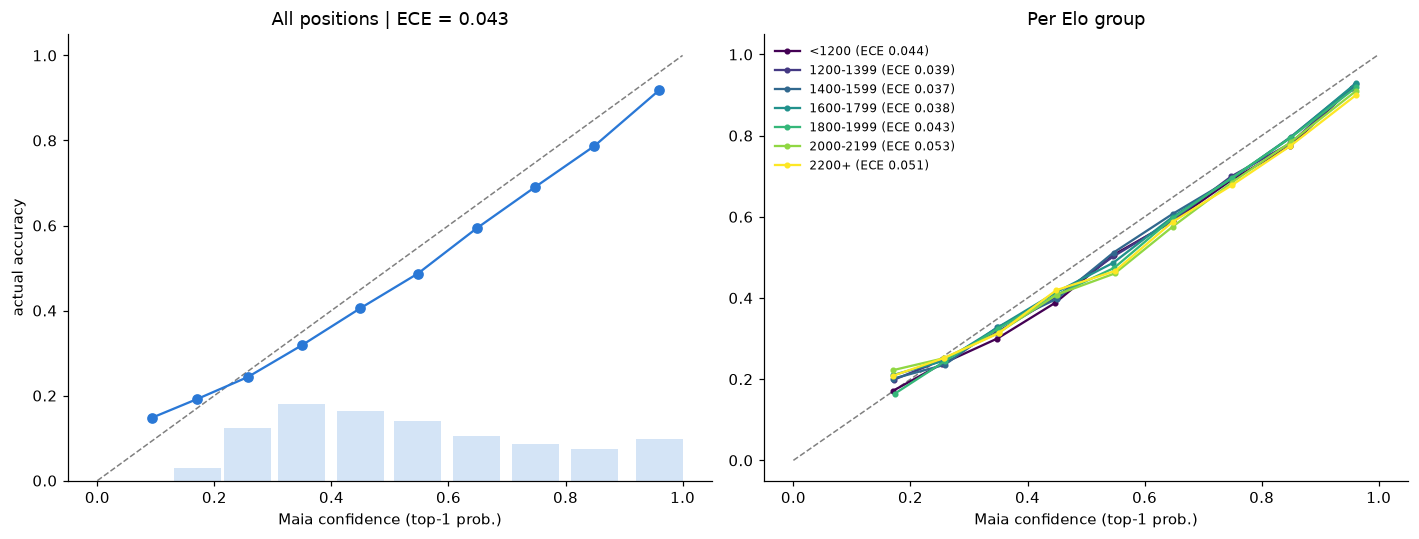

,n,ECE,mean_conf,accuracy,over/under
elo_group,,,,,
<1200,96918,0.044,0.494,0.450,overconfident
1200-1399,83229,0.039,0.522,0.485,overconfident
1400-1599,107390,0.037,0.531,0.496,overconfident
1600-1799,114538,0.038,0.546,0.510,overconfident
1800-1999,108524,0.043,0.555,0.512,overconfident
2000-2199,78018,0.053,0.569,0.517,overconfident
2200+,81142,0.051,0.565,0.515,overconfident


In [2]:
BINS = np.linspace(0, 1, 11)

def calib(d):
    b = pd.cut(d["maia_p_top1"], BINS, include_lowest=True)
    t = d.groupby(b, observed=True).agg(conf=("maia_p_top1", "mean"), acc=("maia_correct", "mean"),
                                        n=("maia_correct", "size"))
    ece = (t["n"] * (t["acc"] - t["conf"]).abs()).sum() / t["n"].sum()
    return t, ece

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
t, ece = calib(df)
axes[0].plot([0, 1], [0, 1], "--", color="grey", lw=1)
axes[0].plot(t["conf"], t["acc"], "o-", color="#2a78d6")
axes[0].bar(t["conf"], t["n"] / t["n"].sum(), width=0.08, alpha=0.2, color="#2a78d6")
axes[0].set(title=f"All positions | ECE = {ece:.3f}", xlabel="Maia confidence (top-1 prob.)", ylabel="actual accuracy")

cmap = plt.get_cmap("viridis", len(ELO_LABELS))
ece_rows = []
axes[1].plot([0, 1], [0, 1], "--", color="grey", lw=1)
for i, eg in enumerate(ELO_LABELS):
    d = df[df["elo_group"] == eg]
    if len(d) < 1000:
        continue
    t, e = calib(d)
    t = t[t["n"] >= 100]
    axes[1].plot(t["conf"], t["acc"], "o-", ms=3, color=cmap(i), label=f"{eg} (ECE {e:.3f})")
    ece_rows.append({"elo_group": eg, "n": len(d), "ECE": e,
                     "mean_conf": d["maia_p_top1"].mean(), "accuracy": d["maia_correct"].mean()})
axes[1].set(title="Per Elo group", xlabel="Maia confidence (top-1 prob.)")
axes[1].legend(fontsize=8, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_elo.png", dpi=200, bbox_inches="tight")
plt.show()

ece_table = pd.DataFrame(ece_rows).set_index("elo_group")
ece_table["over/under"] = np.where(ece_table["mean_conf"] > ece_table["accuracy"], "overconfident", "underconfident")
ece_table.round(3)

## 2. Calibration by phase and time control

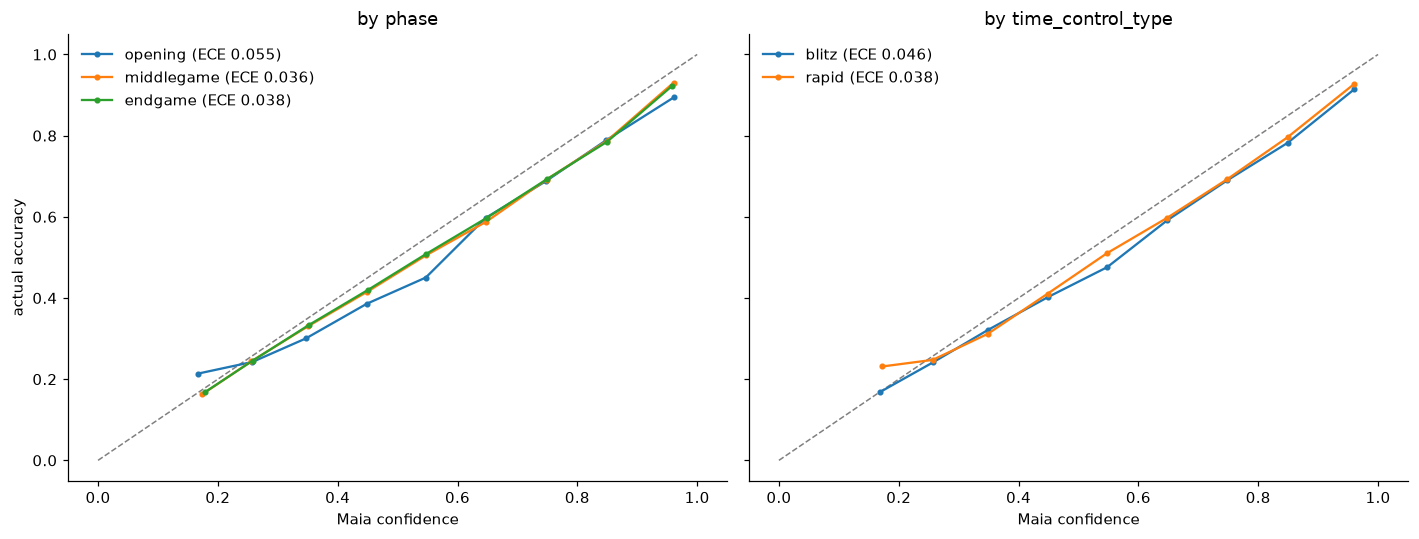

,split,group,n,ECE
0,phase,opening,239456,0.055
1,phase,middlegame,279110,0.036
2,phase,endgame,151193,0.038
3,time_control_type,blitz,440933,0.046
4,time_control_type,rapid,228826,0.038


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
rows = []
for ax, (col, groups) in zip(axes, [("phase", PHASES), ("time_control_type", sorted(df["time_control_type"].unique()))]):
    ax.plot([0, 1], [0, 1], "--", color="grey", lw=1)
    for g in groups:
        d = df[df[col] == g]
        t, e = calib(d)
        t = t[t["n"] >= 100]
        ax.plot(t["conf"], t["acc"], "o-", ms=3, label=f"{g} (ECE {e:.3f})")
        rows.append({"split": col, "group": g, "n": len(d), "ECE": e})
    ax.set(title=f"by {col}", xlabel="Maia confidence")
    ax.legend(frameon=False)
axes[0].set_ylabel("actual accuracy")
fig.tight_layout()
fig.savefig(FIG_DIR / "calibration_phase_tc.png", dpi=200, bbox_inches="tight")
plt.show()
pd.DataFrame(rows).round(3)

➡️ *Findings:* Is Maia over- or under-confident? For which Elo groups / phases is it worst? Connect to the human-only pair's opening result.

## 3. Does Maia fail more on human mistakes?
`move_quality` comes from the engine evaluation in the Lichess data (win-chance drop of the human move).

,n,failure_rate,top3_miss,mean_p_human
move_quality,,,,
good,526798,0.440,0.168,0.427
inaccuracy,64026,0.697,0.358,0.235
mistake,26273,0.736,0.394,0.213
blunder,39668,0.769,0.423,0.196


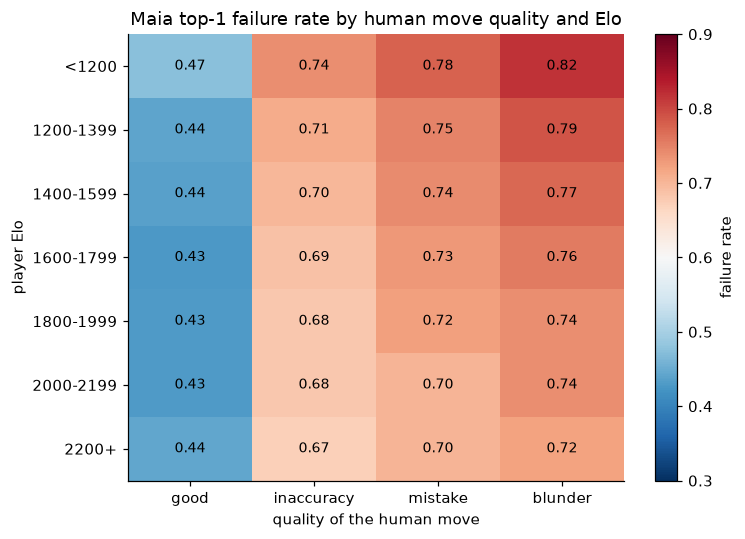

In [4]:
QUAL = ["good", "inaccuracy", "mistake", "blunder"]
q = df.dropna(subset=["move_quality"])
tab = q.groupby("move_quality").agg(n=("failed", "size"), failure_rate=("failed", "mean"),
                                    top3_miss=("maia_top3_hit", lambda s: 1 - s.mean()),
                                    mean_p_human=("maia_p_true", "mean")).reindex(QUAL)
display(tab.round(3))

heat = q.pivot_table(index="elo_group", columns="move_quality", values="failed", aggfunc="mean", observed=True)[QUAL]
cnt = q.pivot_table(index="elo_group", columns="move_quality", values="failed", aggfunc="size", observed=True)[QUAL]
heat = heat.where(cnt >= 100)

fig, ax = plt.subplots(figsize=(7, 5))
im = ax.imshow(heat.to_numpy(), cmap="RdBu_r", vmin=0.3, vmax=0.9, aspect="auto")
ax.set_xticks(range(len(QUAL)), QUAL)
ax.set_yticks(range(len(heat)), heat.index.astype(str))
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.iat[i, j]
        if pd.notna(v):
            ax.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=9)
ax.set(title="Maia top-1 failure rate by human move quality and Elo", xlabel="quality of the human move", ylabel="player Elo")
fig.colorbar(im, ax=ax, label="failure rate")
fig.tight_layout()
fig.savefig(FIG_DIR / "failure_by_move_quality.png", dpi=200, bbox_inches="tight")
plt.show()

**When the human blundered, did Maia at least see the blunder coming?** Distribution of P(human move) for blunders, split by Elo – if low-rated players' blunders get higher probability, Maia has learned *rating-dependent* error patterns.

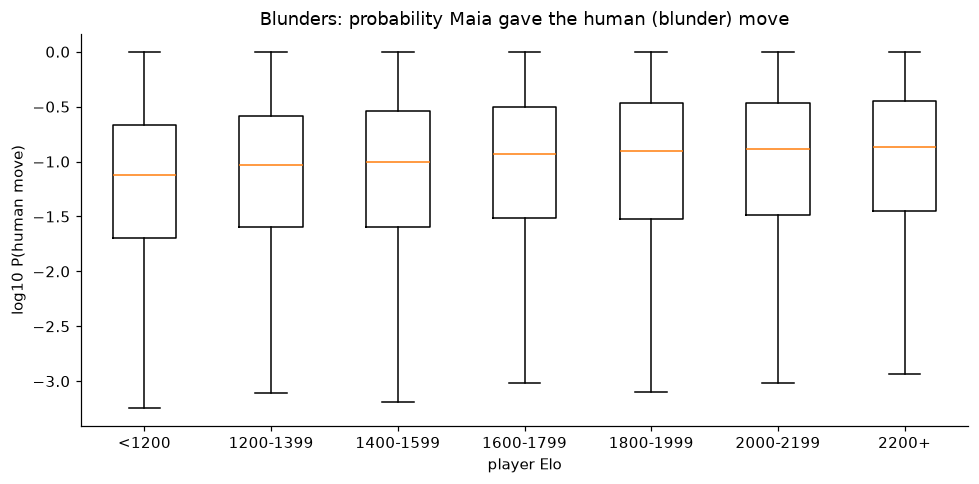

,n,maia_predicted_blunder,median_p
elo_group,,,
<1200,7988,0.182,0.075
1200-1399,5779,0.211,0.093
1400-1599,6723,0.228,0.100
1600-1799,6703,0.245,0.116
1800-1999,5763,0.261,0.124
2000-2199,3730,0.260,0.129
2200+,2982,0.279,0.136


In [5]:
bl = q[q["move_quality"] == "blunder"]
fig, ax = plt.subplots(figsize=(9, 4.5))
data = [np.log10(bl.loc[bl["elo_group"] == eg, "maia_p_true"].clip(1e-4)) for eg in ELO_LABELS]
keep = [i for i, d in enumerate(data) if len(d) >= 50]
ax.boxplot([data[i] for i in keep], showfliers=False)
ax.set_xticks(range(1, len(keep) + 1), [ELO_LABELS[i] for i in keep])
ax.set(title="Blunders: probability Maia gave the human (blunder) move", ylabel="log10 P(human move)", xlabel="player Elo")
fig.tight_layout()
fig.savefig(FIG_DIR / "blunder_ptrue_by_elo.png", dpi=200, bbox_inches="tight")
plt.show()
bl.groupby("elo_group", observed=True).agg(n=("failed", "size"), maia_predicted_blunder=("maia_correct", "mean"),
                                         median_p=("maia_p_true", "median")).round(3)

## 4. Value head vs. engine: does Maia agree about who is winning?
`maia_value_mover` = Maia's predicted win probability for the side to move. `wc_before` = engine win-chance in [-1, 1] for the mover (converted to [0, 1] below).

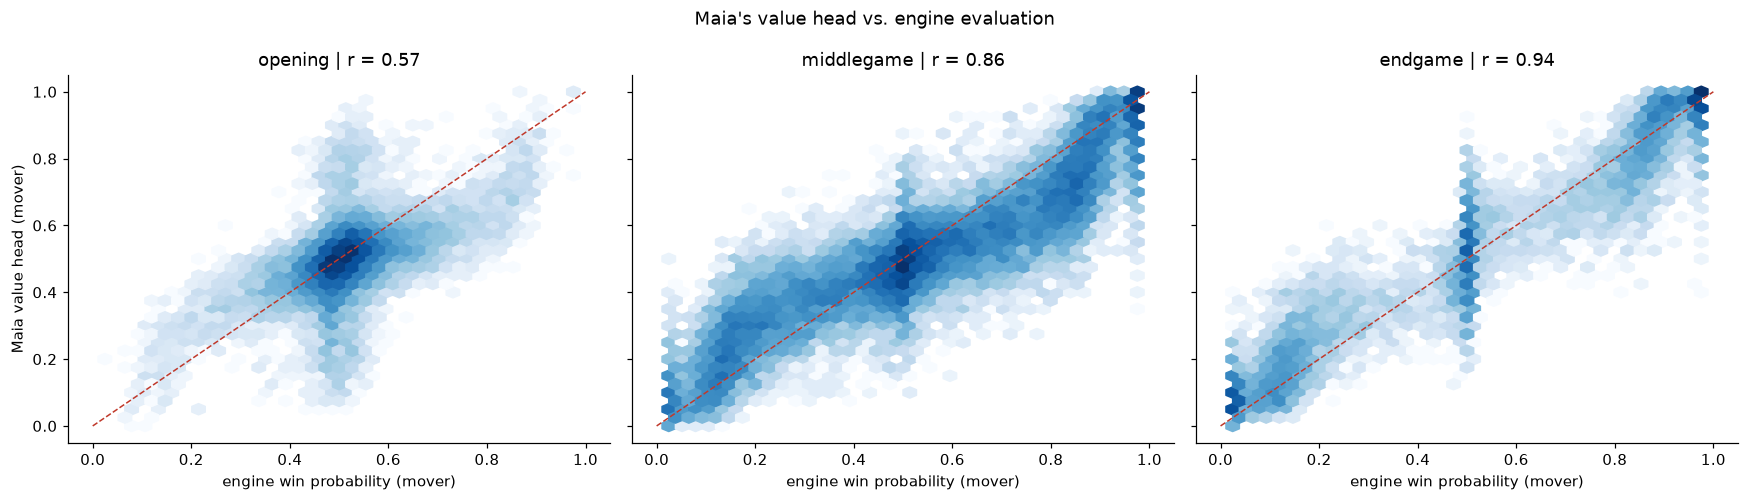

,mean_gap,failure_rate
elo_group,,
<1200,0.106,0.536
1200-1399,0.093,0.512
1400-1599,0.092,0.509
1600-1799,0.090,0.477
1800-1999,0.089,0.479
2000-2199,0.089,0.480
2200+,0.076,0.485


In [6]:
v = df.dropna(subset=["wc_before"]).copy()
v["engine_p"] = (v["wc_before"] + 1) / 2
v = v.sample(min(60000, len(v)), random_state=42)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.6), sharey=True)
for ax, ph in zip(axes, PHASES):
    d = v[v["phase"] == ph]
    ax.hexbin(d["engine_p"], d["maia_value_mover"], gridsize=35, bins="log", cmap="Blues", mincnt=3)
    ax.plot([0, 1], [0, 1], "--", color="#c0392b", lw=1)
    r = np.corrcoef(d["engine_p"], d["maia_value_mover"])[0, 1]
    ax.set(title=f"{ph} | r = {r:.2f}", xlabel="engine win probability (mover)")
axes[0].set_ylabel("Maia value head (mover)")
fig.suptitle("Maia's value head vs. engine evaluation")
fig.tight_layout()
fig.savefig(FIG_DIR / "value_vs_engine.png", dpi=200, bbox_inches="tight")
plt.show()

v["value_gap"] = (v["maia_value_mover"] - v["engine_p"]).abs()
v.groupby("elo_group", observed=True).agg(mean_gap=("value_gap", "mean"),
                                         failure_rate=("failed", "mean")).round(3)

## 5. Summary of findings (fill in)
- **Calibration:** …
- **Human mistakes:** …
- **Value head:** …
- **Compared with the human-only pair:** …
- **Hand-off to Phase II:** …